In [3]:
# ! git clone https://github.com/amazon-science/esci-data.git
# ! cd esci-data
# ! git lfs install
# ! git lfs pull

In [4]:
# !apt-get update -qq
# !apt-get install -y git-lfs

In [5]:
# %cd /content
# !git clone https://github.com/amazon-science/esci-data.git
# %cd /content/esci-data
# !git lfs install
# !git lfs pull

In [6]:
import os

print("Current directory:", os.getcwd())
print("Files:", os.listdir())

Current directory: /content
Files: ['.config', 'esci-data', 'merged.parquet', 'sample_data']


In [7]:
%pip install pandas numpy matplotlib scikit-learn pyarrow

In [8]:
import os

path = "/content/esci-data/shopping_queries_dataset"

print(os.listdir(path))

['shopping_queries_dataset_products.parquet', 'shopping_queries_dataset_examples.parquet', 'shopping_queries_dataset_sources.csv']


# Load the shopping queries dataset examples

In [9]:
import pyarrow.parquet as pa

table1 = pa.read_table("/content/esci-data/shopping_queries_dataset/shopping_queries_dataset_examples.parquet")
table1

pyarrow.Table
example_id: int64
query: string
query_id: int64
product_id: string
product_locale: string
esci_label: string
small_version: int64
large_version: int64
split: string
__index_level_0__: int64
----
example_id: [[0,1,2,3,4,...,131067,131068,131069,131070,131071],[131072,131073,131074,131075,131076,...,262139,262140,262141,262142,262143],...,[2359296,2359297,2359298,2359299,2359300,...,2490363,2490364,2490365,2490366,2490367],[2490368,2490369,2490370,2490371,2490372,...,2621283,2621284,2621285,2621286,2621287]]
query: [[" revent 80 cfm"," revent 80 cfm"," revent 80 cfm"," revent 80 cfm"," revent 80 cfm",...,"90 degrees jacket women","90 degrees jacket women","90 degrees jacket women","90 degrees jacket women","90 degrees jacket women"],["90 degrees jacket women","90 degrees jacket women","90 degrees jacket women","90 degrees jacket women","90 degrees jacket women",...,"baby snack containers","baby snack containers","baby snack containers","baby snack containers","baby snack co

In [10]:
df1 = table1.to_pandas()
# Taking tanspose so the printing dataset will easy.
df1.head().T

,0,1,2,3,4
example_id,0,1,2,3,4
query,revent 80 cfm,revent 80 cfm,revent 80 cfm,revent 80 cfm,revent 80 cfm
query_id,0,0,0,0,0
product_id,B000MOO21W,B07X3Y6B1V,B07WDM7MQQ,B07RH6Z8KW,B07QJ7WYFQ
product_locale,us,us,us,us,us
esci_label,I,E,E,E,E
small_version,0,0,0,0,0
large_version,1,1,1,1,1
split,train,train,train,train,train


In [11]:
df1.head()

,example_id,query,query_id,product_id,product_locale,esci_label,small_version,large_version,split
0,0,revent 80 cfm,0,B000MOO21W,us,I,0,1,train
1,1,revent 80 cfm,0,B07X3Y6B1V,us,E,0,1,train
2,2,revent 80 cfm,0,B07WDM7MQQ,us,E,0,1,train
3,3,revent 80 cfm,0,B07RH6Z8KW,us,E,0,1,train
4,4,revent 80 cfm,0,B07QJ7WYFQ,us,E,0,1,train


In [12]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2621288 entries, 0 to 2621287
Data columns (total 9 columns):
 #   Column          Dtype 
---  ------          ----- 
 0   example_id      int64 
 1   query           object
 2   query_id        int64 
 3   product_id      object
 4   product_locale  object
 5   esci_label      object
 6   small_version   int64 
 7   large_version   int64 
 8   split           object
dtypes: int64(4), object(5)
memory usage: 200.0+ MB


In [13]:
df1.describe()

,example_id,query_id,small_version,large_version
count,2.621288e+06,2.621288e+06,2.621288e+06,2621288.0
mean,1.310644e+06,6.632069e+04,4.265121e-01,1.0
std,7.567008e+05,3.883077e+04,4.945701e-01,0.0
min,0.000000e+00,0.000000e+00,0.000000e+00,1.0
25%,6.553218e+05,3.252575e+04,0.000000e+00,1.0
50%,1.310644e+06,6.647900e+04,0.000000e+00,1.0
75%,1.965965e+06,1.006160e+05,1.000000e+00,1.0
max,2.621287e+06,1.306510e+05,1.000000e+00,1.0


In [14]:
df1['split'].value_counts()

,count
split,
train,1983272
test,638016


# Load the shopping queries dataset products

In [15]:
import pyarrow.parquet as pa

table2 = pa.read_table('/content/esci-data/shopping_queries_dataset/shopping_queries_dataset_products.parquet')
df2 = table1.to_pandas()
df2.head()

,example_id,query,query_id,product_id,product_locale,esci_label,small_version,large_version,split
0,0,revent 80 cfm,0,B000MOO21W,us,I,0,1,train
1,1,revent 80 cfm,0,B07X3Y6B1V,us,E,0,1,train
2,2,revent 80 cfm,0,B07WDM7MQQ,us,E,0,1,train
3,3,revent 80 cfm,0,B07RH6Z8KW,us,E,0,1,train
4,4,revent 80 cfm,0,B07QJ7WYFQ,us,E,0,1,train


In [16]:
print("EXAMPLES COLUMNS:")
print(df1.columns.tolist())

print("\nPRODUCTS COLUMNS:")
print(df2.columns.tolist())

EXAMPLES COLUMNS:
['example_id', 'query', 'query_id', 'product_id', 'product_locale', 'esci_label', 'small_version', 'large_version', 'split']

PRODUCTS COLUMNS:
['example_id', 'query', 'query_id', 'product_id', 'product_locale', 'esci_label', 'small_version', 'large_version', 'split']


In [17]:

# import pandas as pd
# from pathlib import Path

# # Ελέγχουμε το αρχείο απευθείας από τον δίσκο
# path = Path("/home/charis/Desktop/Πτυχιακη/Electronics-Recommendation-System/data/esci_data/esci-data/shopping_queries_dataset/shopping_queries_dataset_products.parquet")

# print("Αρχείο:", path.resolve())
# print("Υπάρχει:", path.exists())

# products_check = pd.read_parquet(path)

# print("\nShape:", products_check.shape)
# print("Columns:", products_check.columns.tolist())

# print("\nΠρώτες εγγραφές:")
# display(products_check.head(3))

# print("\nDuplicate product keys:",
#       products_check.duplicated(
#           subset=["product_id", "product_locale"]
#       ).sum())


# Merge the examples with the products

In [18]:
print("EXAMPLES:", df1.shape)
print("PRODUCTS:", df2.shape)

EXAMPLES: (2621288, 9)
PRODUCTS: (2621288, 9)


In [19]:
# Check for duplicate product keys in the products dataset
keys = ["product_id", "product_locale"]

print(
    "\nDuplicate product keys:",
    df2.duplicated(subset=keys).sum()
)


Duplicate product keys: 806405


In [20]:

import pandas as pd
from pathlib import Path

# 1. Βρίσκουμε τα πραγματικά αρχεία
examples_path = next(
    Path(".").rglob("shopping_queries_dataset_examples.parquet")
)

products_path = next(
    Path(".").rglob("shopping_queries_dataset_products.parquet")
)

# 2. Τα φορτώνουμε σε καινούριες μεταβλητές
esci_examples = pd.read_parquet(examples_path)
esci_products = pd.read_parquet(products_path)

# 3. Ελέγχουμε ότι φορτώθηκαν σωστά
print("EXAMPLES:", esci_examples.shape)
print("PRODUCTS:", esci_products.shape)

print("\nEXAMPLES COLUMNS:")
print(esci_examples.columns.tolist())

print("\nPRODUCTS COLUMNS:")
print(esci_products.columns.tolist())

# 4. Ελέγχουμε ότι ο πίνακας προϊόντων
#    περιέχει πραγματικά πληροφορίες προϊόντων
assert "query" in esci_examples.columns
assert "product_title" in esci_products.columns
assert "query" not in esci_products.columns

# 5. Ελέγχουμε τη μοναδικότητα των προϊόντων
keys = ["product_id", "product_locale"]

duplicate_keys = esci_products.duplicated(
    subset=keys
).sum()

print("\nDuplicate product keys:", duplicate_keys)

# 6. Κάνουμε merge ΜΟΝΟ αν τα keys είναι μοναδικά
if duplicate_keys == 0:
    df_examples_products = esci_examples.merge(
        esci_products,
        on=keys,
        how="left",
        validate="many_to_one"
    )

    print("\nMERGE SUCCESSFUL!")
    print("Rows:", len(df_examples_products))

    display(
        df_examples_products[
            ["query", "product_title", "esci_label"]
        ].head(10)
    )
else:
    print(
        "\nΥπάρχουν πραγματικά διπλότυπα "
        "στο αρχείο προϊόντων. "
        "Χρειάζεται έλεγχος πριν το merge."
    )


EXAMPLES: (2621288, 9)
PRODUCTS: (1814924, 7)

EXAMPLES COLUMNS:
['example_id', 'query', 'query_id', 'product_id', 'product_locale', 'esci_label', 'small_version', 'large_version', 'split']

PRODUCTS COLUMNS:
['product_id', 'product_title', 'product_description', 'product_bullet_point', 'product_brand', 'product_color', 'product_locale']

Duplicate product keys: 0

MERGE SUCCESSFUL!
Rows: 2621288


,query,product_title,esci_label
0,revent 80 cfm,Panasonic FV-20VQ3 WhisperCeiling 190 CFM Ceil...,I
1,revent 80 cfm,Homewerks 7141-80 Bathroom Fan Integrated LED ...,E
2,revent 80 cfm,Homewerks 7140-80 Bathroom Fan Ceiling Mount E...,E
3,revent 80 cfm,Delta Electronics RAD80L BreezRadiance 80 CFM ...,E
4,revent 80 cfm,Panasonic FV-08VRE2 Ventilation Fan with Reces...,E
5,revent 80 cfm,Panasonic FV-0511VQ1 WhisperCeiling DC Ventila...,E
6,revent 80 cfm,Panasonic FV-0510VSL1 WhisperValue DC Ventilat...,E
7,revent 80 cfm,Panasonic FV-0510VS1 WhisperValue DC Ventilati...,E
8,revent 80 cfm,Aero Pure ABF80 L5 W ABF80L5 Ceiling Mount 80 ...,E
9,revent 80 cfm,Delta Electronics (Americas) Ltd. RAD80 Delta ...,E


In [21]:
df_examples_products.head()

,example_id,query,query_id,product_id,product_locale,esci_label,small_version,large_version,split,product_title,product_description,product_bullet_point,product_brand,product_color
0,0,revent 80 cfm,0,B000MOO21W,us,I,0,1,train,Panasonic FV-20VQ3 WhisperCeiling 190 CFM Ceil...,None,WhisperCeiling fans feature a totally enclosed...,Panasonic,White
1,1,revent 80 cfm,0,B07X3Y6B1V,us,E,0,1,train,Homewerks 7141-80 Bathroom Fan Integrated LED ...,None,OUTSTANDING PERFORMANCE: This Homewerk's bath ...,Homewerks,80 CFM
2,2,revent 80 cfm,0,B07WDM7MQQ,us,E,0,1,train,Homewerks 7140-80 Bathroom Fan Ceiling Mount E...,None,OUTSTANDING PERFORMANCE: This Homewerk's bath ...,Homewerks,White
3,3,revent 80 cfm,0,B07RH6Z8KW,us,E,0,1,train,Delta Electronics RAD80L BreezRadiance 80 CFM ...,This pre-owned or refurbished product has been...,Quiet operation at 1.5 sones\nBuilt-in thermos...,DELTA ELECTRONICS (AMERICAS) LTD.,White
4,4,revent 80 cfm,0,B07QJ7WYFQ,us,E,0,1,train,Panasonic FV-08VRE2 Ventilation Fan with Reces...,None,The design solution for Fan/light combinations...,Panasonic,White


In [22]:
df_examples_products.to_csv('merged_csv')

# EDA on Merged Data

In [26]:
# Number of rows and columns
df_examples_products.shape

(2621288, 14)

In [28]:
# Summary of DataFrame
df_examples_products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2621288 entries, 0 to 2621287
Data columns (total 14 columns):
 #   Column                Dtype 
---  ------                ----- 
 0   example_id            int64 
 1   query                 object
 2   query_id              int64 
 3   product_id            object
 4   product_locale        object
 5   esci_label            object
 6   small_version         int64 
 7   large_version         int64 
 8   split                 object
 9   product_title         object
 10  product_description   object
 11  product_bullet_point  object
 12  product_brand         object
 13  product_color         object
dtypes: int64(4), object(10)
memory usage: 280.0+ MB


In [29]:
# Number of duplicate rows
dvalues = df_examples_products.duplicated().sum()

# Convert into DataFrame
duplicate_df = pd.DataFrame({"metric": ["duplicate_rows"], "count": [dvalues]})

# Display DataFrame
duplicate_df

,metric,count
0,duplicate_rows,0


In [30]:
# Number of unique values per feature
nuniq = df_examples_products.nunique().reset_index()

# Rename column names
nuniq.columns = ["feature", "unique values"]

# Display DataFrame
nuniq

,feature,unique values
0,example_id,2621288
1,query,130193
2,query_id,130652
3,product_id,1802772
4,product_locale,3
5,esci_label,4
6,small_version,2
7,large_version,1
8,split,2
9,product_title,1782220


In [24]:
import numpy as np
# Select categorical and numerical columns
cat_cols = list(df_examples_products.select_dtypes(include=["object"]).columns)
num_cols = list(df_examples_products.select_dtypes(include=[np.number]).columns)

In [31]:
# Statistical summary of numerical data
df_examples_products[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
example_id,2621288.0,1310643.50,756700.81,0.0,655321.75,1310643.5,1965965.25,2621287.0
query_id,2621288.0,66320.69,38830.77,0.0,32525.75,66479.0,100616.00,130651.0
small_version,2621288.0,0.43,0.49,0.0,0.00,0.0,1.00,1.0
large_version,2621288.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0


# Univariate analysis of numerical Columns

In [32]:
!pip install seaborn

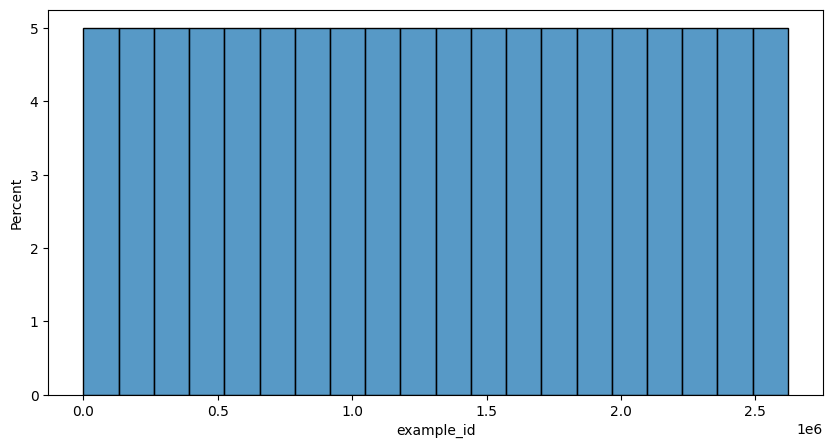

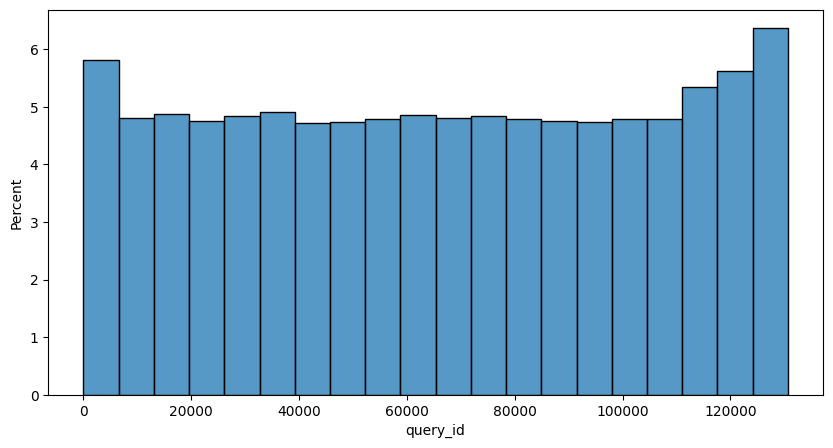

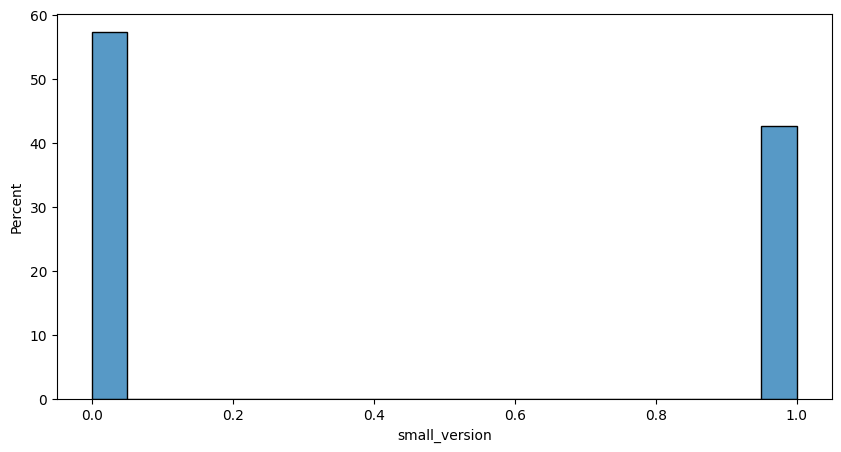

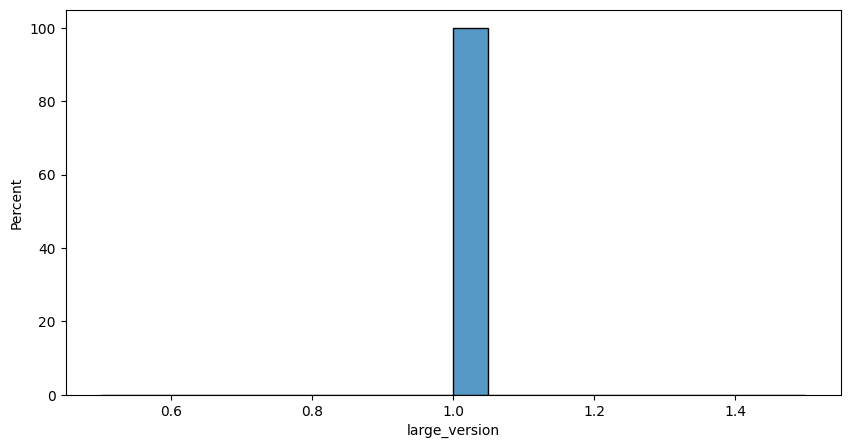

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

for col in num_cols:
    plt.figure(figsize=(10, 5))

    ax = sns.histplot(
        data=df_examples_products,
        x=col,
        stat='percent',
        bins=20
    )

# Univariate analysis of Categorical Columns

In [34]:
import seaborn as sns
import matplotlib.pyplot as plt

for col in cat_cols:
    plt.figure(figsize=(10, 5))

    ax = sns.histplot(
        data=df_examples_products,
        x=col,
        stat='percent',
        bins=20
    )

: 

: 

: 